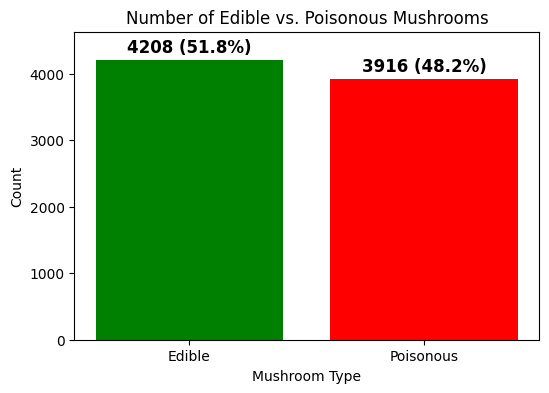

In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


# Load the dataset
df = pd.read_csv("mushrooms.csv")


df.drop(columns=['veil-type','stalk-root'], inplace=True)

label_encoders = {}
for col in df.columns:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    label_encoders[col] = le


class_counts = df.iloc[:, 0].value_counts()
total = class_counts.sum()
percentages = (class_counts / total) * 100

# Plot the bar chart
plt.figure(figsize=(6, 4))
bars = plt.bar(class_counts.index, class_counts.values, color=['green', 'red'])

# Add labels with actual numbers and percentages (with vertical offset)
for bar, count, percent in zip(bars, class_counts.values, percentages):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 50,  # Adjust vertical offset
             f"{count} ({percent:.1f}%)", 
             ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.xlabel("Mushroom Type")
plt.ylabel("Count")
plt.title("Number of Edible vs. Poisonous Mushrooms")
plt.xticks(ticks=[0, 1], labels=['Edible', 'Poisonous'], rotation=0)
plt.ylim(0, class_counts.max() * 1.1)  # Add some space at the top for labels
plt.show()


C:\Users\Amjad\AppData\Local\Temp\ipykernel_8024\565389587.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_corr.values, y=class_corr.index, palette='coolwarm')


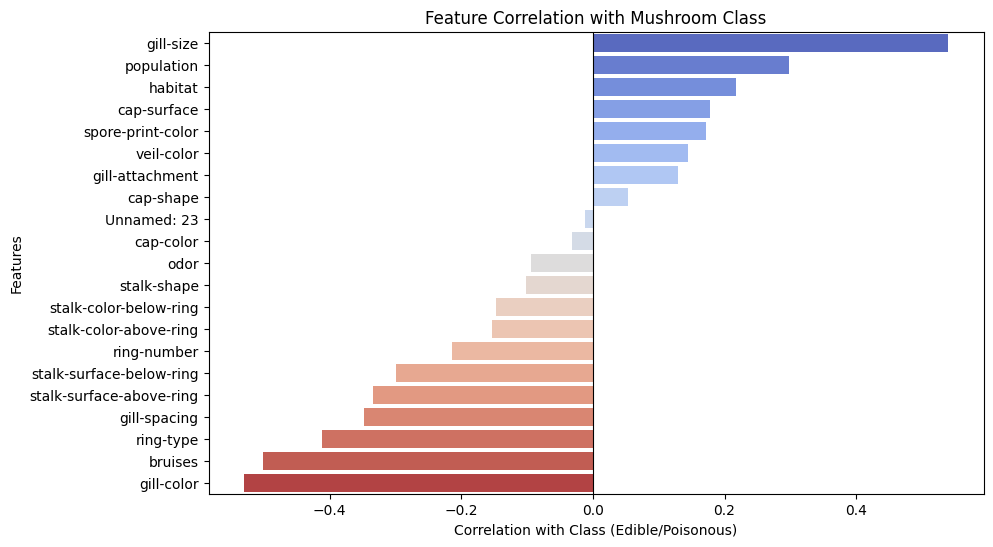

In [4]:
df_encoded = df.apply(lambda col: col.astype('category').cat.codes)

# Compute the correlation matrix
corr_matrix = df_encoded.corr()

# Get only the correlations with the class column (first row)
class_corr = corr_matrix.iloc[0, 1:].sort_values(ascending=False)  # Exclude self-correlation

# Plot as a horizontal bar chart
plt.figure(figsize=(10, 6))
sns.barplot(x=class_corr.values, y=class_corr.index, palette='coolwarm')

plt.xlabel("Correlation with Class (Edible/Poisonous)")
plt.ylabel("Features")
plt.title("Feature Correlation with Mushroom Class")
plt.axvline(0, color='black', linewidth=0.8)  # Add vertical line at 0 for reference
plt.show()

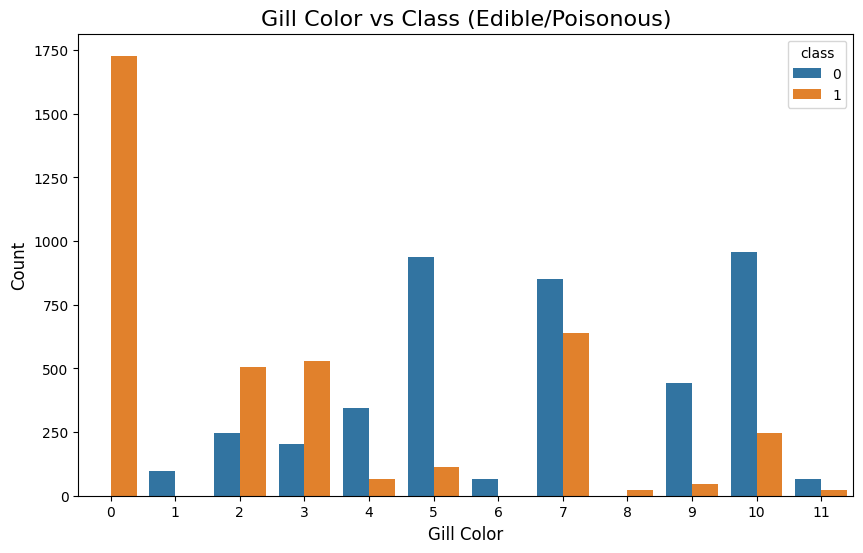

In [5]:
# Create a countplot to visualize the relationship between gill-color and class
plt.figure(figsize=(10, 6))
sns.countplot(x='gill-color', hue='class', data=df)

# Add labels and title
plt.title('Gill Color vs Class (Edible/Poisonous)', fontsize=16)
plt.xlabel('Gill Color', fontsize=12)
plt.ylabel('Count', fontsize=12)

# Display the plot
plt.show()


C:\Users\Amjad\AppData\Local\Temp\ipykernel_8024\4097893912.py:12: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  ax = sns.barplot(x='bruises', hue='class', y='count', data=count_data, ci=None)


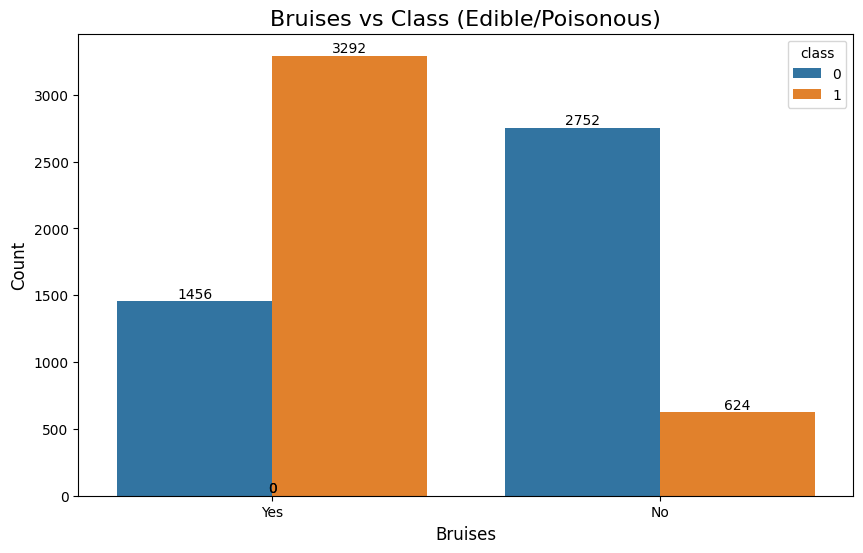

In [6]:
# Count the occurrences of each 'bruises' and 'class' combination
count_data = df.groupby(['bruises', 'class']).size().reset_index(name='count')

# Filter out combinations where 'count' is zero
count_data = count_data[count_data['count'] > 0]

# Ensure only the existing bruises categories are plotted (filter out '0' if it's empty)
valid_bruises = count_data['bruises'].unique()

# Create the plot using filtered data
plt.figure(figsize=(10, 6))
ax = sns.barplot(x='bruises', hue='class', y='count', data=count_data, ci=None)

# Remove the unwanted x-tick for '0' if there's no data
if 0 not in valid_bruises:
    ax.set_xticks([1])
    ax.set_xticklabels(['Yes'])

# Change x-axis labels to 'Yes' and 'No'
plt.xticks(ticks=[0, 1], labels=['Yes', 'No'])

# Add labels and title
plt.title('Bruises vs Class (Edible/Poisonous)', fontsize=16)
plt.xlabel('Bruises', fontsize=12)
plt.ylabel('Count', fontsize=12)

# Add the count labels on top of the bars
for p in ax.patches:
    height = p.get_height()
    x = p.get_x() + p.get_width() / 2  # Position for the text
    y = p.get_y() + height             # Position for the text
    
    # Add the count text
    ax.text(x, y + 0.2, f'{int(height)}', ha='center', va='bottom', fontsize=10)

# Display the plot
plt.show()





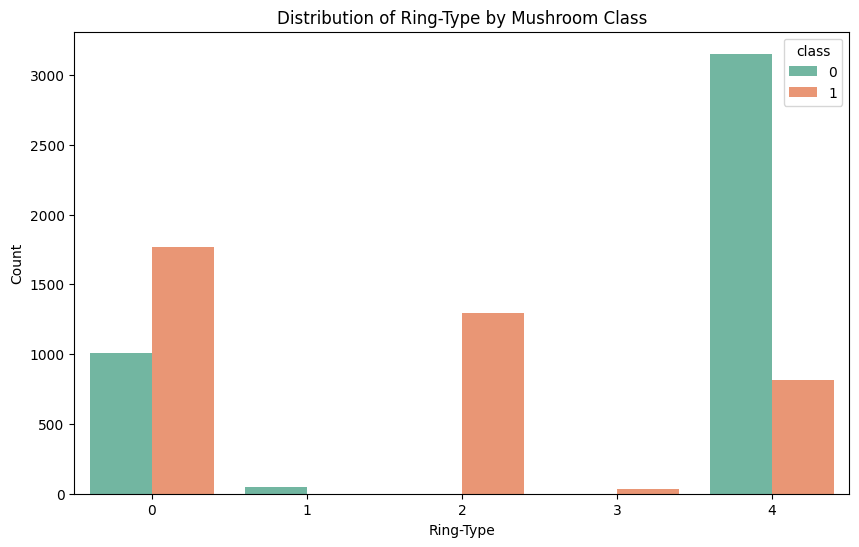

In [7]:
plt.figure(figsize=(10, 6))

# Create a count plot to visualize the relationship between 'ring-type' and 'class'
sns.countplot(data=df, x='ring-type', hue='class', palette='Set2')

# Add labels and title
plt.title('Distribution of Ring-Type by Mushroom Class')
plt.xlabel('Ring-Type')
plt.ylabel('Count')

# Show the plot
plt.show()

In [8]:
X = df.drop(columns=['class'])
y = df['class']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [9]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


model = LogisticRegression()
svm_model = SVC(kernel='linear', random_state=42)
model.fit(X_train, y_train)
svm_model.fit(X_train, y_train)


y_pred = model.predict(X_test)
y_pred_svm = svm_model.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy * 100:.2f}%")
svm_accuracy = accuracy_score(y_test, y_pred_svm)
print(f"SVM Accuracy: {svm_accuracy * 100:.2f}%")

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)
cm1 = confusion_matrix(y_test, y_pred_svm)
print("Confusion Matrix:")
print(cm1)

# Classification Report
print("Classification Report:")
print(classification_report(y_test, y_pred))

print("\nSVM Classification Report:\n", classification_report(y_test, y_pred_svm))


Accuracy: 94.40%
SVM Accuracy: 95.75%
Confusion Matrix:
[[796  47]
 [ 44 738]]
Confusion Matrix:
[[804  39]
 [ 30 752]]
Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.94      0.95       843
           1       0.94      0.94      0.94       782

    accuracy                           0.94      1625
   macro avg       0.94      0.94      0.94      1625
weighted avg       0.94      0.94      0.94      1625


SVM Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.95      0.96       843
           1       0.95      0.96      0.96       782

    accuracy                           0.96      1625
   macro avg       0.96      0.96      0.96      1625
weighted avg       0.96      0.96      0.96      1625



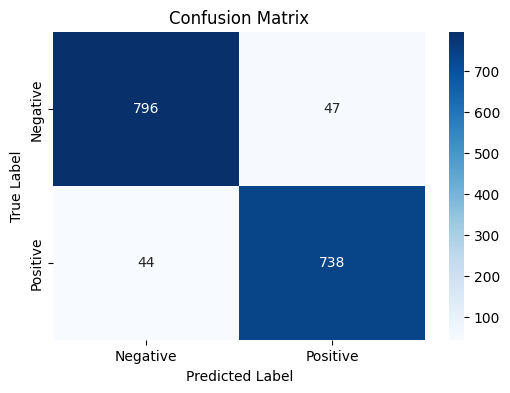

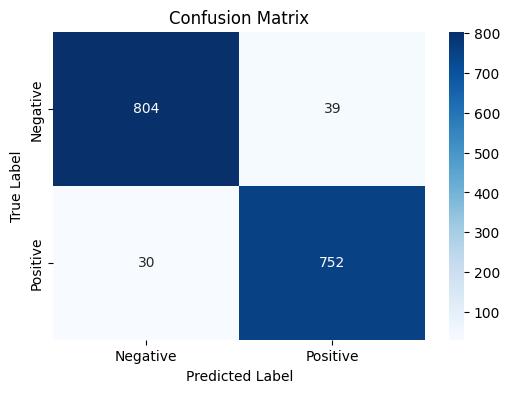

In [12]:
plt.figure(figsize=(6, 4))  
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()

plt.figure(figsize=(6, 4))  
sns.heatmap(cm1, annot=True, fmt='d', cmap='Blues', xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()


In [ ]:
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)
rf_accuracy = accuracy_score(y_test, y_pred_rf)

cm2 = confusion_matrix(y_test, y_pred_rf)
print("Confusion Matrix:")
print(cm2)


print("Random Forest Accuracy:", rf_accuracy)

print("\nRandom Forest Classification Report:\n", classification_report(y_test, y_pred_rf))



Confusion Matrix:
[[843   0]
 [  0 782]]
Random Forest Accuracy: 1.0

Random Forest Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00       843
           1       1.00      1.00      1.00       782

    accuracy                           1.00      1625
   macro avg       1.00      1.00      1.00      1625
weighted avg       1.00      1.00      1.00      1625



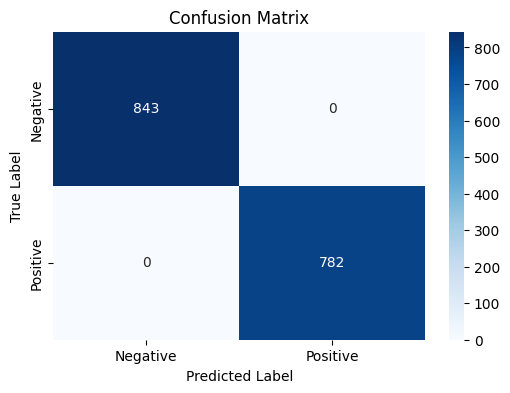

In [13]:
plt.figure(figsize=(6, 4))  
sns.heatmap(cm2, annot=True, fmt='d', cmap='Blues', xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()
